# Homework 4
### 1 Re-Use Homework 3 Code

In [41]:
from pathlib import Path
import pandas as pd

data_dir = Path("AReM")

print("Notebook working directory:", Path.cwd())
print("Data folder exists:", data_dir.is_dir())

files = sorted(data_dir.glob("*/dataset*.csv"))
print("Total CSV files:", len(files))

for folder in sorted(p for p in data_dir.iterdir() if p.is_dir()):
    print(f"{folder.name}: {len(list(folder.glob('dataset*.csv')))} files")

Notebook working directory: /Users/bt/Documents/DSCI 552/Homework 4
Data folder exists: True
Total CSV files: 88
bending1: 7 files
bending2: 6 files
cycling: 15 files
lying: 15 files
sitting: 15 files
standing: 15 files
walking: 15 files


In [42]:
records = []

for path in files:
    activity = path.parent.name
    dataset_number = int(path.stem.removeprefix("dataset"))

    test_limit = 2 if activity in {"bending1", "bending2"} else 3
    split = "test" if dataset_number <= test_limit else "train"

    records.append({
        "activity": activity,
        "dataset_number": dataset_number,
        "split": split,
        "path": path,
    })

manifest = pd.DataFrame(records)

display(
    manifest.groupby(["activity", "split"])
    .size()
    .unstack(fill_value=0)
)

print(manifest["split"].value_counts())

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


split
train    69
test     19
Name: count, dtype: int64


In [43]:
from collections import Counter

problems = []

for path in files:
    with path.open(encoding="utf-8-sig") as handle:
        rows = [
            line.strip()
            for line in handle
            if line.strip() and not line.lstrip().startswith("#")
        ]

    field_counts = Counter(row.count(",") + 1 for row in rows)

    if len(rows) != 480 or field_counts != Counter({7: 480}):
        problems.append((str(path), len(rows), dict(field_counts)))

print("Files needing inspection:", len(problems))
for problem in problems:
    print(problem)

Files needing inspection: 4
('AReM/bending2/dataset4.csv', 480, {1: 480})
('AReM/cycling/dataset14.csv', 480, {7: 479, 8: 1})
('AReM/cycling/dataset9.csv', 480, {7: 479, 8: 1})
('AReM/sitting/dataset8.csv', 479, {7: 479})


In [44]:
problem_paths = [
    data_dir / "bending2/dataset4.csv",
    data_dir / "cycling/dataset14.csv",
    data_dir / "cycling/dataset9.csv",
    data_dir / "sitting/dataset8.csv",
]

for path in problem_paths:
    with path.open(encoding="utf-8-sig") as handle:
        rows = [
            (line_number, line.strip())
            for line_number, line in enumerate(handle, start=1)
            if line.strip() and not line.lstrip().startswith("#")
        ]

    print(f"\n{path}")
    print("First two:", rows[:2])
    print("Last two:", rows[-2:])

    unusual = [
        i for i, (_, text) in enumerate(rows)
        if text.count(",") + 1 != 7
    ]

    # Show nearby rows for a few format errors, not all 480.
    for i in unusual[:2]:
        print("Around unusual row:")
        for nearby in rows[max(0, i - 1):i + 2]:
            print(nearby)

    if path.name == "dataset8.csv" and path.parent.name == "sitting":
        times = [float(text.split(",")[0]) for _, text in rows]
        steps = [b - a for a, b in zip(times, times[1:])]
        print("Time-step counts:", __import__("collections").Counter(steps))


AReM/bending2/dataset4.csv
First two: [(6, '0 32.50 0.50 0.00 0.00 19.00 1.00'), (7, '250 32.50 0.50 0.00 0.00 18.50 0.50')]
Last two: [(484, '119500 28.00 0.00 5.00 0.82 17.00 0.71'), (485, '119750 28.00 0.00 0.00 0.00 17.00 1.00')]
Around unusual row:
(6, '0 32.50 0.50 0.00 0.00 19.00 1.00')
(7, '250 32.50 0.50 0.00 0.00 18.50 0.50')
Around unusual row:
(6, '0 32.50 0.50 0.00 0.00 19.00 1.00')
(7, '250 32.50 0.50 0.00 0.00 18.50 0.50')
(8, '500 32.75 0.43 1.00 0.00 18.00 0.00')

AReM/cycling/dataset14.csv
First two: [(6, '0,35.75,1.79,21.00,2.45,20.50,0.50'), (7, '250,38.75,1.48,17.00,4.32,19.67,2.05')]
Last two: [(484, '119500,33.33,6.18,15.50,3.77,17.00,4.32'), (485, '119750,34.00,2.12,24.50,1.80,22.25,2.59,')]
Around unusual row:
(484, '119500,33.33,6.18,15.50,3.77,17.00,4.32')
(485, '119750,34.00,2.12,24.50,1.80,22.25,2.59,')

AReM/cycling/dataset9.csv
First two: [(6, '0,41.67,0.47,17.67,2.87,14.50,2.06'), (7, '250,42.00,2.12,9.67,6.34,14.75,2.49')]
Last two: [(484, '119500,34.2

In [45]:
sensor_cols = [
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23",
]
expected_time = pd.Index(range(0, 120000, 250), name="time")


def load_instance(path):
    rows = []

    with path.open(encoding="utf-8-sig") as handle:
        for line_number, raw_line in enumerate(handle, start=1):
            line = raw_line.strip()

            if not line or line.startswith("#"):
                continue

            parts = line.split(",") if "," in line else line.split()

            # Remove an extra empty field caused by a trailing comma.
            if len(parts) == 8 and parts[-1] == "":
                parts = parts[:-1]

            if len(parts) != 7:
                raise ValueError(
                    f"{path}, line {line_number}: expected 7 fields, got {len(parts)}"
                )

            rows.append([float(value) for value in parts])

    frame = pd.DataFrame(rows, columns=["time", *sensor_cols])
    frame["time"] = frame["time"].astype(int)

    if not frame["time"].is_unique:
        raise ValueError(f"Duplicate times in {path}")

    missing = expected_time.difference(frame["time"])
    extra = pd.Index(frame["time"]).difference(expected_time)

    if len(extra):
        raise ValueError(f"Unexpected times in {path}: {list(extra)}")

    if len(missing):
        if path.parent.name == "sitting" and path.name == "dataset8.csv" and len(missing) == 1:
            print(f"Interpolating missing time {missing[0]} in {path}")
            frame = frame.set_index("time").reindex(expected_time)
            frame[sensor_cols] = frame[sensor_cols].interpolate(
                method="index", limit_area="inside"
            )
            frame = frame.reset_index()
        else:
            raise ValueError(f"Unexpected missing times in {path}: {list(missing)}")

    if len(frame) != 480 or frame[sensor_cols].isna().any().any():
        raise ValueError(f"Incomplete data after cleaning: {path}")

    return frame


instances = {path: load_instance(path) for path in files}

print("Instances loaded:", len(instances))
print("Rows per instance:", set(len(frame) for frame in instances.values()))

Interpolating missing time 13500 in AReM/sitting/dataset8.csv
Instances loaded: 88
Rows per instance: {480}


In [46]:
feature_rows = []

for row in manifest.itertuples(index=False):
    frame = instances[row.path]

    result = {
        "instance": len(feature_rows) + 1,
        "file": str(row.path),
        "activity": row.activity,
        "split": row.split,
    }

    ### 1(c)ii
    # Extract the time-domain features minimum, maximum, mean, median, stan-dard deviation,
    # first quartile, and third quartile for all of the 6 time series in each instance.
    for i, column in enumerate(sensor_cols, start=1):
        series = frame[column]

        result[f"min{i}"] = series.min()
        result[f"max{i}"] = series.max()
        result[f"mean{i}"] = series.mean()
        result[f"median{i}"] = series.median()
        result[f"std{i}"] = series.std(ddof=1)
        result[f"q1_{i}"] = series.quantile(0.25)
        result[f"q3_{i}"] = series.quantile(0.75)

    feature_rows.append(result)

features_df = pd.DataFrame(feature_rows)

feature_order = [
    column
    for i in range(1, 7)
    for column in (
        f"min{i}", f"max{i}", f"mean{i}", f"median{i}",
        f"std{i}", f"q1_{i}", f"q3_{i}"
    )
]

quartile_names = {
    **{f"q1_{i}": f"1st quart{i}" for i in range(1, 7)},
    **{f"q3_{i}": f"3rd quart{i}" for i in range(1, 7)},
}

print(len(feature_order))  # 42
print(feature_order[:7])  # the seven features from time series 1

metadata_cols = ["instance", "file", "activity", "split"]
feature_cols = [col for col in features_df if col not in metadata_cols]

print("Table shape:", features_df.shape)
print("Numeric feature columns:", len(feature_cols))
print("Missing feature values:", features_df[feature_cols].isna().sum().sum())
display(features_df.head())

42
['min1', 'max1', 'mean1', 'median1', 'std1', 'q1_1', 'q3_1']
Table shape: (88, 46)
Numeric feature columns: 42
Missing feature values: 0


,instance,file,activity,split,min1,max1,mean1,median1,std1,q1_1,...,std5,q1_5,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6
0,1,AReM/bending1/dataset1.csv,bending1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,2,AReM/bending1/dataset2.csv,bending1,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,3,AReM/bending1/dataset3.csv,bending1,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,4,AReM/bending1/dataset4.csv,bending1,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,5,AReM/bending1/dataset5.csv,bending1,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [47]:
import numpy as np
from scipy.stats import bootstrap

def sample_std(values, axis=-1):
    return np.std(values, axis=axis, ddof=1)

rng = np.random.default_rng(552)
results = []

for column in feature_order:
    values = features_df[column].to_numpy(dtype=float)

    boot = bootstrap(
        (values,),
        sample_std,
        vectorized=True,
        confidence_level=0.90,
        n_resamples=10_000,
        method="percentile",
        rng=rng,
    )

    results.append({
        "feature": quartile_names.get(column, column),
        "std_estimate": sample_std(values),
        "ci_lower": boot.confidence_interval.low,
        "ci_upper": boot.confidence_interval.high,
    })

In [48]:
std_ci_df = pd.DataFrame(results)

selected_columns = [
    f"{feature_type}{i}"
    for feature_type in ("mean", "std", "max")
    for i in range(1, 7)
]

selected_ci_df = (
    std_ci_df.set_index("feature")
    .loc[selected_columns]
    .reset_index()
)

print("Selected features:", len(selected_ci_df))
display(selected_ci_df.round(4))

print("All features:", len(std_ci_df))
display(std_ci_df.round(4))

Selected features: 18


,feature,std_estimate,ci_lower,ci_upper
0,mean1,5.3357,4.7128,5.8836
1,mean2,1.5742,1.3908,1.7068
2,mean3,4.0084,3.4124,4.4867
3,mean4,1.1661,1.0775,1.2225
4,mean5,5.6756,4.4258,6.7405
5,mean6,1.1548,1.0631,1.2157
6,std1,1.7722,1.5726,1.9494
7,std2,0.8841,0.8032,0.9420
8,std3,0.9467,0.7618,1.1219
9,std4,0.4582,0.4203,0.4856


All features: 42


,feature,std_estimate,ci_lower,ci_upper
0,min1,9.5700,8.2569,10.7417
1,max1,4.3944,3.3280,5.3082
2,mean1,5.3357,4.7128,5.8836
3,median1,5.4401,4.8092,5.9993
4,std1,1.7722,1.5726,1.9494
5,1st quart1,6.1536,5.5706,6.6526
6,3rd quart1,5.1389,4.3307,5.8409
7,min2,0.0000,0.0000,0.0000
8,max2,5.0627,4.6327,5.4113
9,mean2,1.5742,1.3908,1.7068


### 2(a) Binary Classification using Logistic Regression
#### (a)i Scatter Plots

In [49]:
import matplotlib.pyplot as plt

train_df = features_df.loc[features_df["split"] == "train"].copy()

train_df["binary_class"] = np.where(
    train_df["activity"].isin(["bending1", "bending2"]),
    "Bending",
    "Other",
)

print(train_df["binary_class"].value_counts())

binary_class
Other      60
Bending     9
Name: count, dtype: int64


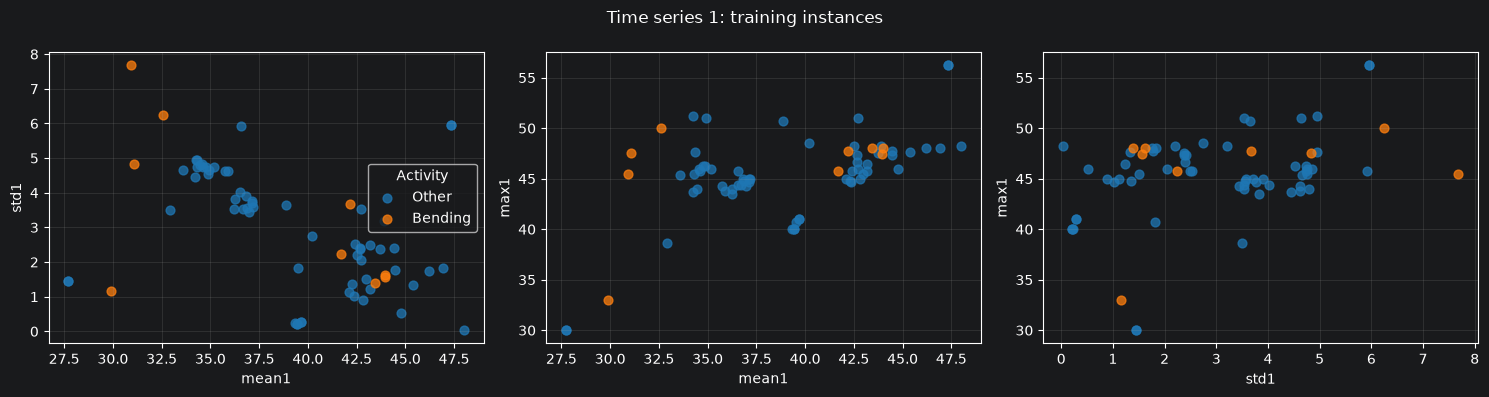

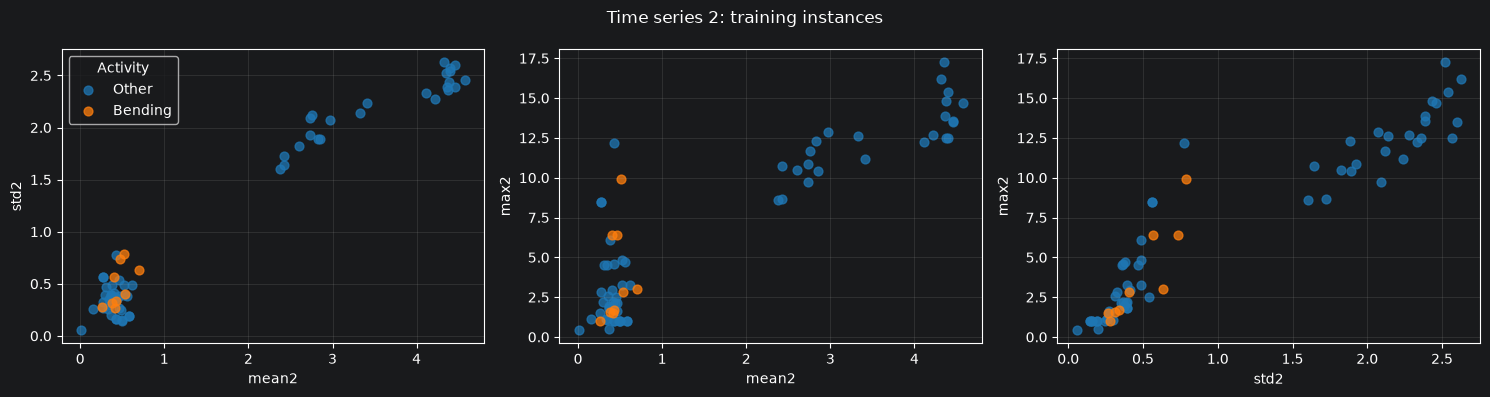

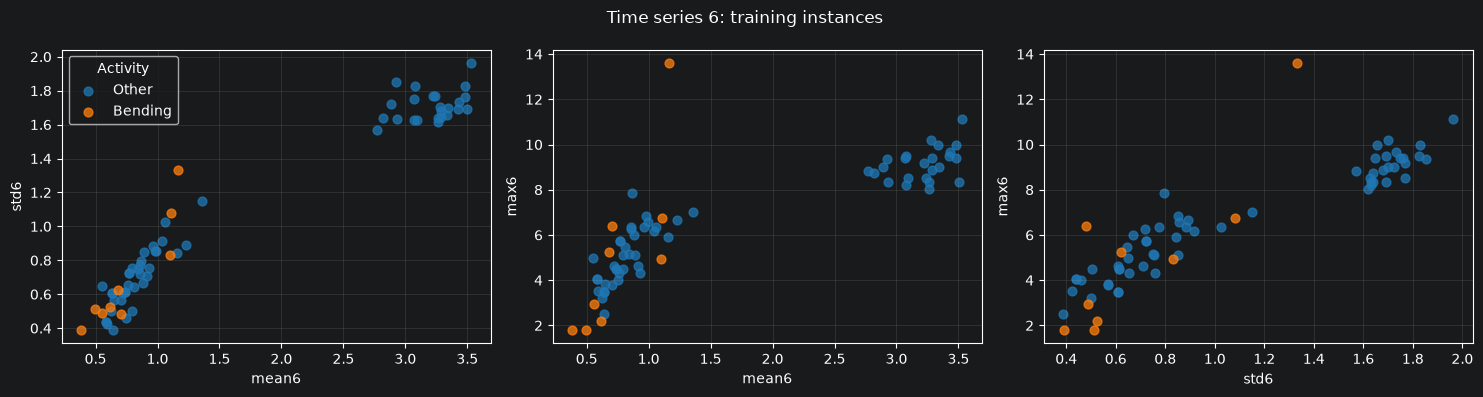

In [50]:
feature_pairs = [
    ("mean", "std"),
    ("mean", "max"),
    ("std", "max"),
]
colors = {"Bending": "tab:orange", "Other": "tab:blue"}

for series_number in (1, 2, 6):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, (x_feature, y_feature) in zip(axes, feature_pairs):
        x_col = f"{x_feature}{series_number}"
        y_col = f"{y_feature}{series_number}"

        for group in ("Other", "Bending"):
            points = train_df.loc[train_df["binary_class"] == group]
            ax.scatter(
                points[x_col],
                points[y_col],
                color=colors[group],
                label=group,
                alpha=0.75,
                s=40,
            )

        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.grid(alpha=0.2)

    axes[0].legend(title="Activity")
    fig.suptitle(f"Time series {series_number}: training instances")
    fig.tight_layout()
    plt.show()

The three features show differences mostly seen in Time Series 1 where all bending points are very spread out and are somewhat differentiated from the other activities. But in Times Series 2 and 6, we can see that none of the pairwise plots show a clean separation between bending and other datapoints.

#### 2(a)ii Split 2 Time Series

In [51]:
two_part_rows = []

for row in manifest.itertuples(index=False):
    if row.split != "train":
        continue

    frame = instances[row.path]

    result = {
        "file": str(row.path),
        "activity": row.activity,
        "binary_class": (
            "Bending"
            if row.activity in {"bending1", "bending2"}
            else "Other"
        ),
    }

    for series_number, column in enumerate(sensor_cols, start=1):
        halves = (frame[column].iloc[:240], frame[column].iloc[240:])

        for part_number, half in enumerate(halves, start=1):
            assert len(half) == 240

            result[f"mean{series_number}_part{part_number}"] = half.mean()
            result[f"std{series_number}_part{part_number}"] = half.std(ddof=1)
            result[f"max{series_number}_part{part_number}"] = half.max()

    two_part_rows.append(result)

two_part_df = pd.DataFrame(two_part_rows)

print("Shape:", two_part_df.shape)
print(two_part_df["binary_class"].value_counts())

Shape: (69, 39)
binary_class
Other      60
Bending     9
Name: count, dtype: int64


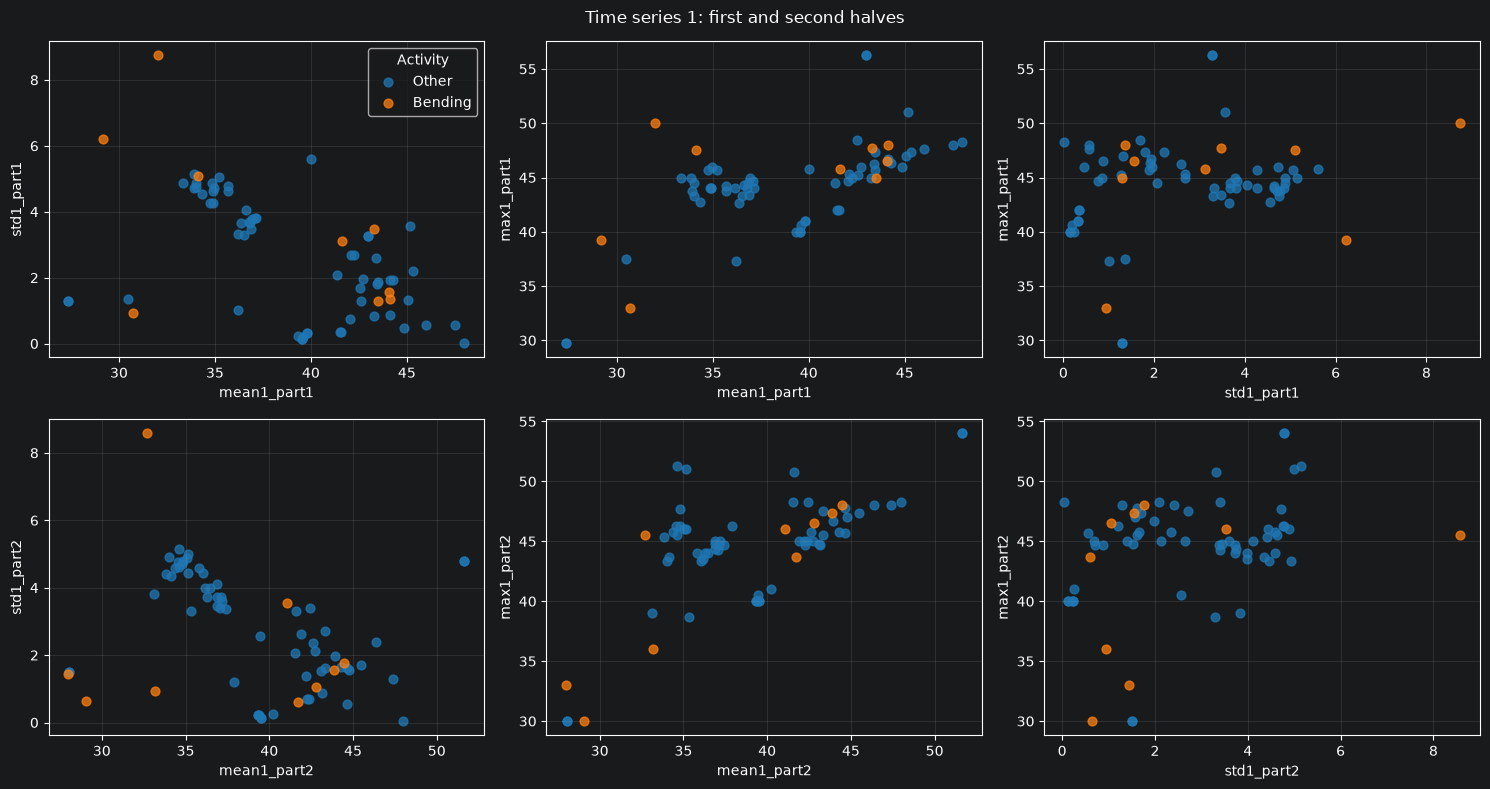

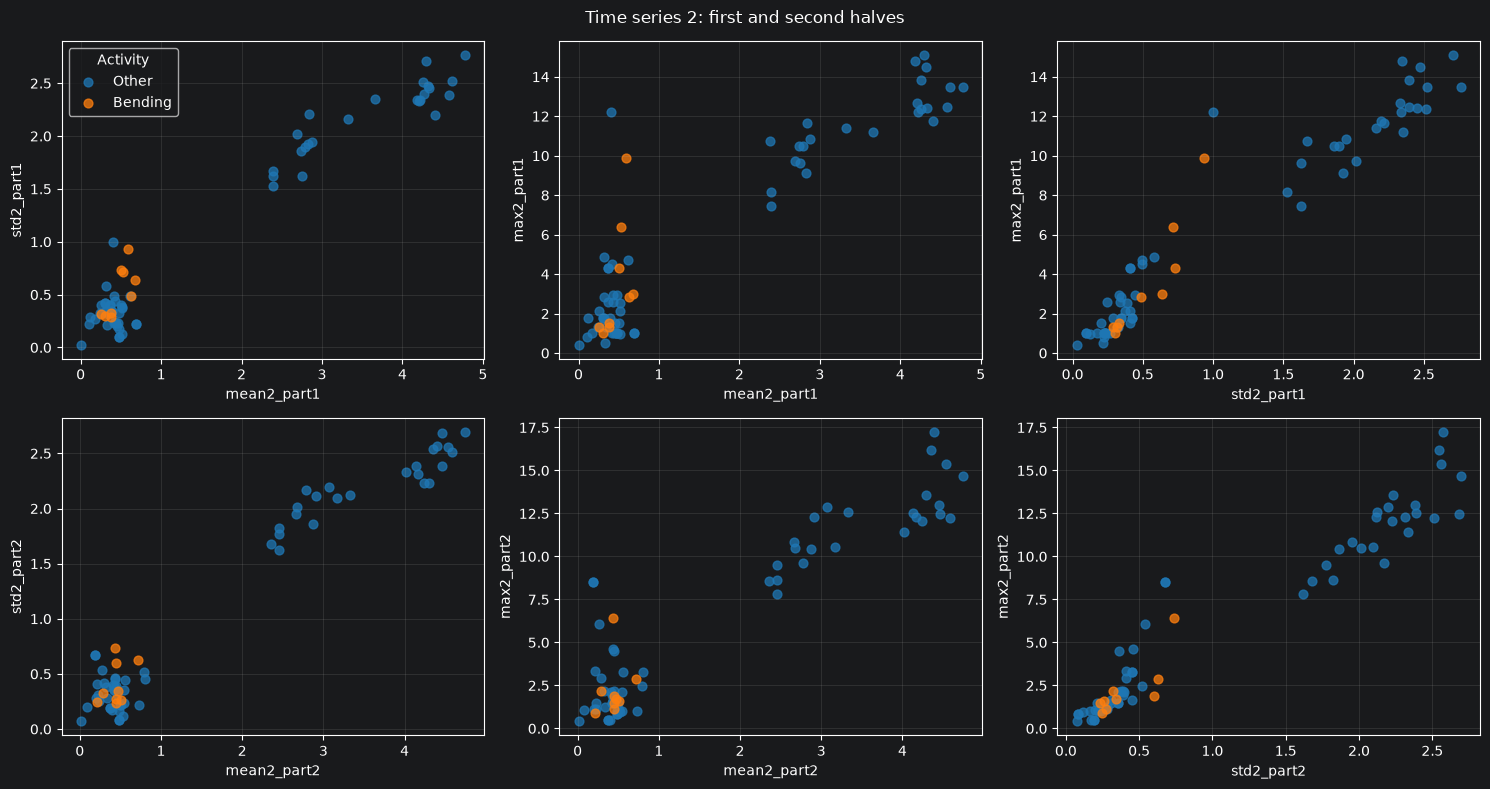

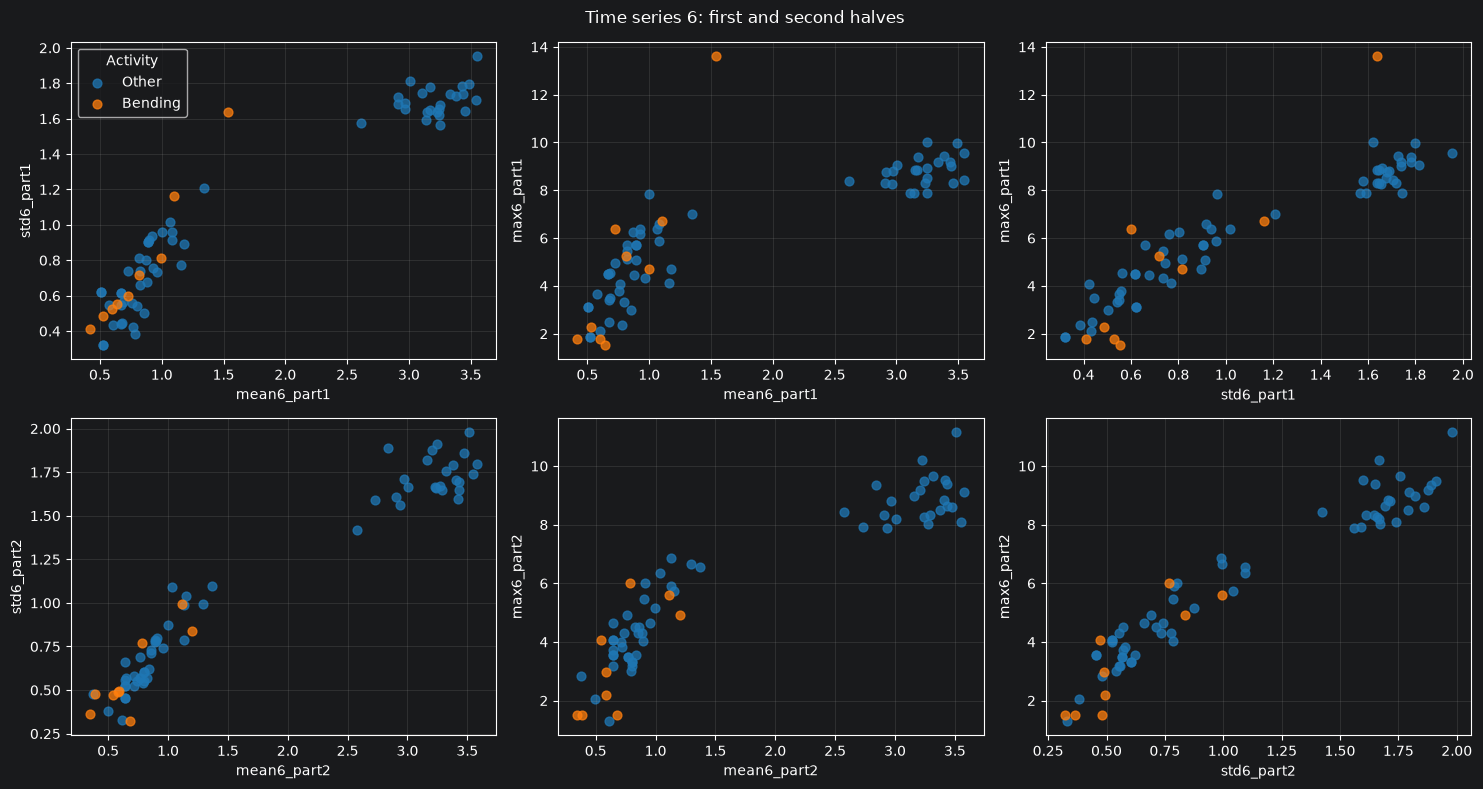

In [52]:
import matplotlib.pyplot as plt

feature_pairs = [("mean", "std"), ("mean", "max"), ("std", "max")]
colors = {"Bending": "tab:orange", "Other": "tab:blue"}

for series_number in (1, 2, 6):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))

    for part_number in (1, 2):
        for pair_number, (x_feature, y_feature) in enumerate(feature_pairs):
            ax = axes[part_number - 1, pair_number]
            x_col = f"{x_feature}{series_number}_part{part_number}"
            y_col = f"{y_feature}{series_number}_part{part_number}"

            for group in ("Other", "Bending"):
                points = two_part_df.loc[two_part_df["binary_class"] == group]
                ax.scatter(
                    points[x_col],
                    points[y_col],
                    color=colors[group],
                    label=group,
                    alpha=0.75,
                    s=40,
                )

            ax.set_xlabel(x_col)
            ax.set_ylabel(y_col)
            ax.grid(alpha=0.2)

    axes[0, 0].legend(title="Activity")
    fig.suptitle(f"Time series {series_number}: first and second halves")
    fig.tight_layout()
    plt.show()

After splitting each training set into equal time series ranges, we can't really observe much difference still. We se a big group of other activities have larger values while the bending points often still stick quite close to the lower value group. No separation can be seen.

#### 2(a)iii Logistical Regression to Solve Binary Classification

In [53]:
train_manifest = manifest.loc[manifest["split"] == "train"].reset_index(drop=True)
y_train = train_manifest["activity"].isin(["bending1", "bending2"]).astype(int)

def make_split_features(rows, l):
    feature_rows = []

    for row in rows.itertuples(index=False):
        frame = instances[row.path]
        features = {}

        for series_number, column in enumerate(sensor_cols, start=1):
            # Consecutive pieces, kept in time order
            pieces = np.array_split(frame[column].to_numpy(dtype=float), l)

            for part_number, values in enumerate(pieces, start=1):
                suffix = f"{series_number}_part{part_number}"
                features[f"min{suffix}"] = values.min()
                features[f"max{suffix}"] = values.max()
                features[f"mean{suffix}"] = values.mean()
                features[f"median{suffix}"] = np.median(values)
                features[f"std{suffix}"] = values.std(ddof=1)
                features[f"q1_{suffix}"] = np.quantile(values, 0.25)
                features[f"q3_{suffix}"] = np.quantile(values, 0.75)

        feature_rows.append(features)

    return pd.DataFrame(feature_rows)

X_by_l = {
    l: make_split_features(train_manifest, l)
    for l in range(1, 21)
}

print("Training recordings:", len(y_train))
print("l=1 shape:", X_by_l[1].shape)
print("l=2 shape:", X_by_l[2].shape)
print("l=20 shape:", X_by_l[20].shape)
print("Class counts:")
print(y_train.value_counts())

Training recordings: 69
l=1 shape: (69, 42)
l=2 shape: (69, 84)
l=20 shape: (69, 840)
Class counts:
activity
0    60
1     9
Name: count, dtype: int64


In [65]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
p_candidates = [1, 2, 3, 5, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
cv_results = []

for l, X in X_by_l.items():
    for p in p_candidates:
        if p > X.shape[1]:
            continue

        fold_accuracies = []
        fold_balanced_accuracies = []

        for train_idx, validation_idx in cv.split(X, y_train):
            model = make_pipeline(
                StandardScaler(),
                RFE(
                    estimator=LogisticRegression(C=1e4, max_iter=500),
                    n_features_to_select=p,
                    step=0.5,
                ),
                LogisticRegression(C=1e4, max_iter=500),
            )

            model.fit(X.iloc[train_idx], y_train.iloc[train_idx])
            predictions = model.predict(X.iloc[validation_idx])

            actual = y_train.iloc[validation_idx]
            fold_accuracies.append((predictions == actual).mean())
            fold_balanced_accuracies.append(
                balanced_accuracy_score(actual, predictions)
            )

        cv_results.append({
            "l": l,
            "p": p,
            "cv_accuracy": np.mean(fold_accuracies),
            "cv_balanced_accuracy": np.mean(fold_balanced_accuracies),
        })

cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values(
        ["cv_accuracy", "cv_balanced_accuracy", "p", "l"],
        ascending=[False, False, True, True],
    )
    .reset_index(drop=True)
)

display(cv_results_df.head(10))

best_l = int(cv_results_df.loc[0, "l"])
best_p = int(cv_results_df.loc[0, "p"])

print(f"Best pair among the values tried: l={best_l}, p={best_p}")

,l,p,cv_accuracy,cv_balanced_accuracy
0,1,15,0.985714,0.991667
1,1,3,0.985714,0.950000
2,1,5,0.971429,0.941667
3,1,13,0.971429,0.941667
4,1,16,0.971429,0.941667
5,1,17,0.971429,0.941667
6,1,18,0.971429,0.941667
7,1,20,0.971429,0.941667
8,1,2,0.971429,0.900000
9,3,3,0.971429,0.900000


Best pair among the values tried: l=1, p=15


In [66]:
# Best pair found in 2(a)iii
best_l = 1
best_p = 15

final_model = make_pipeline(
    StandardScaler(),
    RFE(
        estimator=LogisticRegression(C=1e4, max_iter=500),
        n_features_to_select=best_p,
        step=0.5,
    ),
    LogisticRegression(C=1e4, max_iter=500),
)

final_model.fit(X_by_l[best_l], y_train)

selected_features = X_by_l[best_l].columns[
    final_model.named_steps["rfe"].support_
].tolist()

print(f"Fitted model: l={best_l}, p={best_p}")
print(f"Selected {len(selected_features)} features:")
print(selected_features)

Fitted model: l=1, p=15
Selected 15 features:
['min1_part1', 'max1_part1', 'mean1_part1', 'q3_1_part1', 'max2_part1', 'max3_part1', 'q3_3_part1', 'max4_part1', 'median4_part1', 'min5_part1', 'max5_part1', 'mean5_part1', 'median6_part1', 'std6_part1', 'q1_6_part1']


Because we sorted the values by highest to lowest, we can see that the best pair has an l: 1 and p: 15. This means the ideal split of the data is 1, keeping all 480 rows and the best RFE choice in this case is 15 features out of the 42 possible.

#### 2(a)iv Confusion Matrix Report and Coefficients and P-Values

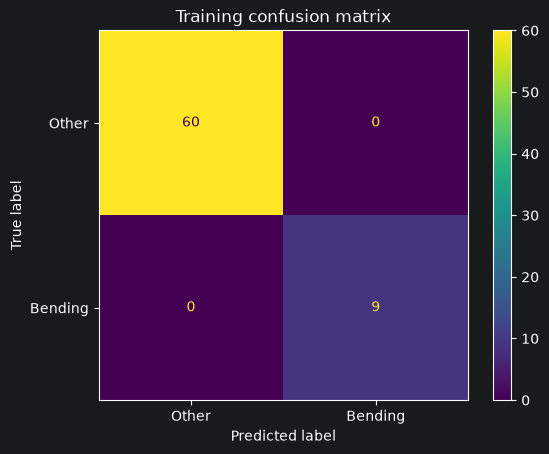

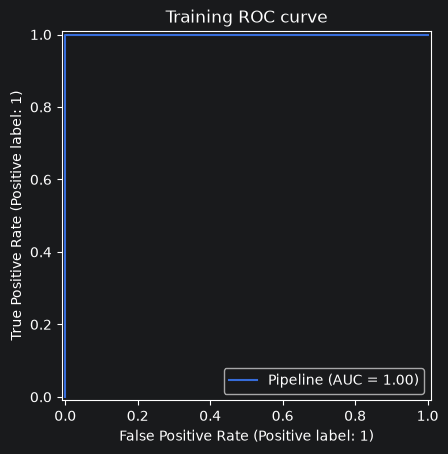

Training AUC: 1.000


,feature,beta
0,intercept,-9.6361
1,min1_part1,-1.6574
2,max1_part1,1.5263
3,mean1_part1,-1.1884
4,q3_1_part1,-2.4499
5,max2_part1,-1.6561
6,max3_part1,0.6797
7,q3_3_part1,-1.8139
8,max4_part1,1.6201
9,median4_part1,-1.0819


In [55]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
)

X_train = X_by_l[best_l]

ConfusionMatrixDisplay.from_estimator(
    final_model, X_train, y_train,
    labels=[0, 1],
    display_labels=["Other", "Bending"],
)
plt.title("Training confusion matrix")
plt.show()

RocCurveDisplay.from_estimator(final_model, X_train, y_train)
plt.title("Training ROC curve")
plt.show()

auc = roc_auc_score(y_train, final_model.predict_proba(X_train)[:, 1])
print(f"Training AUC: {auc:.3f}")

logistic_fit = final_model.named_steps["logisticregression"]
display(pd.DataFrame({
    "feature": ["intercept", *selected_features],
    "beta": [logistic_fit.intercept_[0], *logistic_fit.coef_[0]],
}).round(4))

The classifier classified all 69 training instances with a training AUC of 1.00. The logistic regression on the other hand produced extremely large standard errors, so its coefficient p-values are not informative and are very unreliable. On top of that  This is consistent with separation of the training classes.

#### 2(a)v Testing the Classifier on the Test Set

Cross-validation accuracy: 0.986
Test accuracy:             1.000
Correct test predictions:  19/19


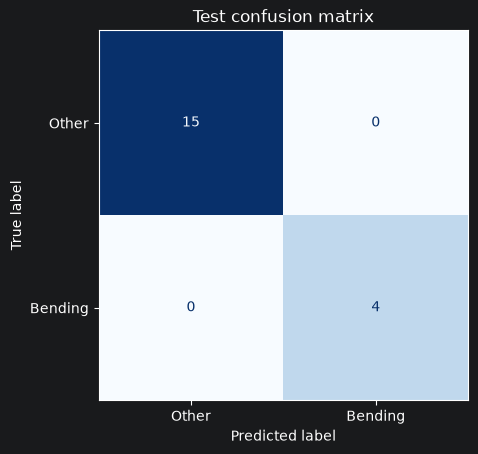

In [56]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

test_manifest = manifest.loc[
    manifest["split"] == "test"
].reset_index(drop=True)

X_test = make_split_features(test_manifest, best_l)
y_test = test_manifest["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

# Test features must have the same names and order as training features.
assert X_test.columns.equals(X_by_l[best_l].columns)
assert len(X_test) == len(y_test) == 19

test_predictions = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)

cv_accuracy = cv_results_df.loc[
    (cv_results_df["l"] == best_l) &
    (cv_results_df["p"] == best_p),
    "cv_accuracy"
].iloc[0]

print(f"Cross-validation accuracy: {cv_accuracy:.3f}")
print(f"Test accuracy:             {test_accuracy:.3f}")
print(f"Correct test predictions:  {(test_predictions == y_test).sum()}/19")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "Bending"],
    cmap="Blues",
    colorbar=False,
)
plt.title("Test confusion matrix")
plt.show()

The test accuracy was 100% (19/19 recordings), which is slightly higher than the cross-validation accuracy of 98.6%. The model correctly classified both activity groups in the test set. This supports the cross-validation result, although the test set is small, with only four bending recordings.

#### 2(a)vi Separation Instability?
To answer the question, Yes the classes of the training data were very separated. The bending and other training instances appear to be separated by the selected features. The training confusion matrix has no errors, and the training AUC is 1.00. The unpenalized logistic regression produced extremely large standard errors, indicating unstable coefficient estimates. Its p-values should therefore not be interpreted.

#### 2(a)vii Imbalanced Classes?
Yes, the classes are imbalanced: training data contained 9 Bending and 60 Other recordings; test contains 4 Bending and 15 Other. The confusion matrices show these class counts even though both models classified their respective sets perfectly. We can create a balanced training sample with 9 of the bending records in the training set and add another 9 random training recordings. With that we can have a 50% even dataset.

Yes. The original training set contains 9 Bending and 60 Other recordings; the test set contains 4 Bending and 15 Other recordings. To address the imbalance, I kept all nine Bending training recordings and randomly selected nine Other training recordings. I fitted a new logistic regression model to this balanced sample and adjusted its intercept by −1.897 to reflect the Bending proportion in the original training set.

On the full training set, the adjusted model correctly classified all 60 Other recordings and 7 of 9 Bending recordings. Its training accuracy was 97.1% and its AUC was 1.00. On the unchanged test set, it correctly classified all 19 recordings, with 100% accuracy and AUC = 1.00. The training AUC can be perfect despite two classification errors because AUC considers the ranking of predictions across all thresholds, while the confusion matrix uses a single threshold.

Case-control sample counts:
activity
1    9
0    9
Name: count, dtype: int64
Intercept adjustment: -1.897
Adjusted intercept: -1.918

Training accuracy: 0.971
Training AUC: 1.000


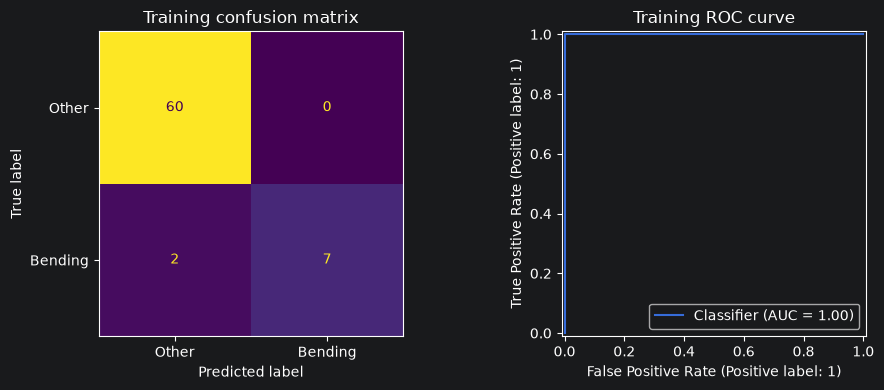


Test accuracy: 1.000
Test AUC: 1.000


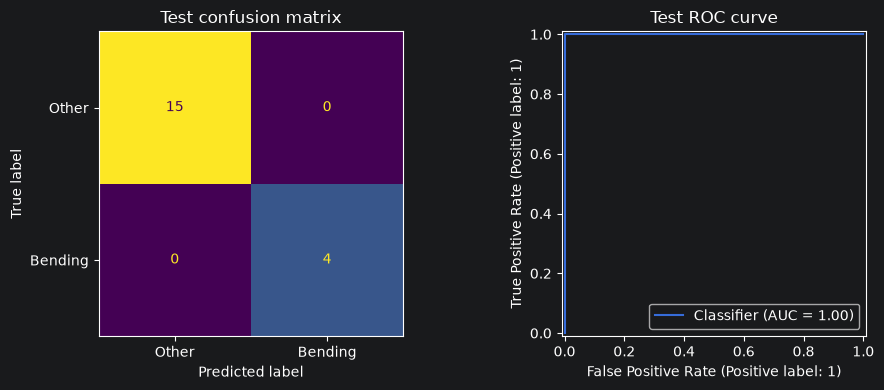

In [57]:
from sklearn.metrics import (
    accuracy_score, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(552)

bending_idx = np.flatnonzero(y_train.to_numpy() == 1)
other_idx = np.flatnonzero(y_train.to_numpy() == 0)

sampled_other_idx = rng.choice(
    other_idx, size=len(bending_idx), replace=False
)
case_idx = np.concatenate([bending_idx, sampled_other_idx])

# Use the 15 features already selected using training data.
X_case = X_by_l[best_l].iloc[case_idx][selected_features]
y_case = y_train.iloc[case_idx]

print("Case-control sample counts:")
print(y_case.value_counts())

case_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000),
)
case_model.fit(X_case, y_case)

# Correct the intercept for the class proportion in the full training set.
sample_rate = y_case.mean()       # 9/18 = 0.5
training_rate = y_train.mean()    # 9/69

intercept_adjustment = (
    np.log(training_rate / (1 - training_rate))
    - np.log(sample_rate / (1 - sample_rate))
)

logistic_fit = case_model.named_steps["logisticregression"]
logistic_fit.intercept_[0] += intercept_adjustment

print(f"Intercept adjustment: {intercept_adjustment:.3f}")
print(f"Adjusted intercept: {logistic_fit.intercept_[0]:.3f}")

for name, X, y in [
    ("Training", X_by_l[best_l][selected_features], y_train),
    ("Test", X_test[selected_features], y_test),
]:
    predictions = case_model.predict(X)
    probabilities = case_model.predict_proba(X)[:, 1]

    print(f"\n{name} accuracy: {accuracy_score(y, predictions):.3f}")
    print(f"{name} AUC: {roc_auc_score(y, probabilities):.3f}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    ConfusionMatrixDisplay.from_predictions(
        y, predictions,
        labels=[0, 1],
        display_labels=["Other", "Bending"],
        colorbar=False,
        ax=axes[0],
    )
    axes[0].set_title(f"{name} confusion matrix")

    RocCurveDisplay.from_predictions(
        y, probabilities, ax=axes[1]
    )
    axes[1].set_title(f"{name} ROC curve")

    plt.tight_layout()
    plt.show()

The best logistic regression model in my cross-validation search used the complete time series l=1 and p=15 selected features. Its cross-validation accuracy was 98.6%, and it correctly classified all 19 test recordings. The training classes appeared to be separated, which made the unpenalized coefficient estimates and p-values unreliable. The classes were also imbalanced. After balancing the training sample and adjusting the new model’s intercept, test accuracy remained 100%, although that model missed two Bending recordings when evaluated on the full training set. Because the test set contains only four Bending recordings, these results are promising but limited.

### 2(b) Binary Classification Using Penalized Logistic Regression
#### 2(b)i Create a Penalized 2(a)iii
Rechoose L and C

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
C_candidates = [0.001, 0.01, 0.1, 1, 10, 100]
l1_results = []

for l in range(1, 21):
    for C in C_candidates:
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                l1_ratio=1,
                solver="liblinear",
                C=C,  # use l1_best_C in the final-model cell
                max_iter=2000,
                random_state=552,
            )
        )

        scores = cross_validate(
            model,
            X_by_l[l],
            y_train,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy",
            },
            error_score="raise",
        )

        l1_results.append({
            "l": l,
            "C": C,
            "cv_accuracy": scores["test_accuracy"].mean(),
            "cv_balanced_accuracy":
                scores["test_balanced_accuracy"].mean(),
        })

l1_results_df = (
    pd.DataFrame(l1_results)
    .sort_values(
        ["cv_accuracy", "cv_balanced_accuracy", "l", "C"],
        ascending=[False, False, True, True],
    )
    .reset_index(drop=True)
)

display(l1_results_df.head(10))

l1_best_l = int(l1_results_df.loc[0, "l"])
l1_best_C = float(l1_results_df.loc[0, "C"])

print(f"Chosen l: {l1_best_l}")
print(f"Chosen C: {l1_best_C}")

,l,C,cv_accuracy,cv_balanced_accuracy
0,1,1.0,0.985714,0.950000
1,1,10.0,0.971429,0.941667
2,1,100.0,0.971429,0.941667
3,12,1.0,0.971429,0.941667
4,12,10.0,0.971429,0.941667
5,13,1.0,0.971429,0.900000
6,20,1.0,0.971429,0.900000
7,2,100.0,0.957143,0.933333
8,3,1.0,0.957143,0.891667
9,3,10.0,0.957143,0.891667


Chosen l: 1
Chosen C: 1.0


L1 cross-validation accuracy: 0.986
L1 test accuracy: 1.000
Features with nonzero coefficients: 12


,feature,coefficient
0,min1_part1,-0.5042
6,q3_1_part1,-2.1591
8,max2_part1,-0.5992
17,median3_part1,-0.4233
19,q1_3_part1,-0.1106
20,q3_3_part1,-0.7415
22,max4_part1,1.0483
26,q1_4_part1,-1.6635
28,min5_part1,4.4360
29,max5_part1,4.8268


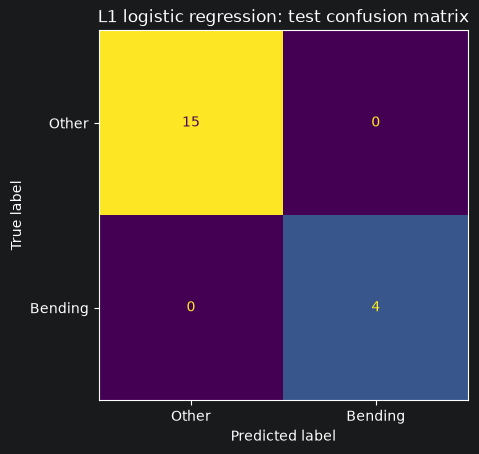

In [59]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

l1_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        C=C,  # use l1_best_C in the final-model cell
        max_iter=2000,
        random_state=552,
    )
)

X_train_l1 = X_by_l[l1_best_l]
X_test_l1 = make_split_features(test_manifest, l1_best_l)

assert X_train_l1.columns.equals(X_test_l1.columns)

l1_model.fit(X_train_l1, y_train)
l1_predictions = l1_model.predict(X_test_l1)

l1_cv_accuracy = l1_results_df.loc[0, "cv_accuracy"]
l1_test_accuracy = accuracy_score(y_test, l1_predictions)

coefficients = l1_model.named_steps["logisticregression"].coef_[0]
retained_features = pd.DataFrame({
    "feature": X_train_l1.columns,
    "coefficient": coefficients,
})
retained_features = retained_features.loc[
    retained_features["coefficient"].abs() > 1e-8
]

print(f"L1 cross-validation accuracy: {l1_cv_accuracy:.3f}")
print(f"L1 test accuracy: {l1_test_accuracy:.3f}")
print(f"Features with nonzero coefficients: {len(retained_features)}")
display(retained_features.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    l1_predictions,
    labels=[0, 1],
    display_labels=["Other", "Bending"],
    colorbar=False,
)
plt.title("L1 logistic regression: test confusion matrix")
plt.show()

#### 2(b)ii Compare P-Values of Penalized Regression vs Variable Selection

After RFE selected 15 features, a separate unpenalized logistic regression fit produced extremely large standard errors, making its p-values unreliable. Therefore, I used the RFE alternative permitted in 2(a)iii rather than p-value selection. L1 and RFE both achieved 98.6% cross-validation accuracy and 100% test accuracy. L1 retained 12 features with nonzero coefficients, while RFE retained 15. L1 was easier to implement because it selected features during model fitting. I cannot compare either method’s accuracy with p-value selection because a reliable p-value-selected model was not obtained.

### 2(c) Multi-Class Classification
#### 2(c)i Multinomial Regression

Include all 7 activities

In [60]:
y_train_multi = train_manifest["activity"].reset_index(drop=True)
y_test_multi = test_manifest["activity"].reset_index(drop=True)

print("Training counts by activity:")
print(y_train_multi.value_counts())

cv_multi = StratifiedKFold(
    n_splits=4, shuffle=True, random_state=552
)

multi_C_candidates = [0.01, 0.1, 1, 2, 3, 4, 5, 10, 100]
multi_results = []

for l in range(1, 21):
    for C in multi_C_candidates:
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                l1_ratio=1,
                solver="saga",
                C=C,
                max_iter=5000,
                tol=1e-3,
                random_state=552,
            ),
        )

        scores = cross_validate(
            model,
            X_by_l[l],
            y_train_multi,
            cv=cv_multi,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy",
            },
            error_score="raise",
        )

        multi_results.append({
            "l": l,
            "C": C,
            "cv_accuracy": scores["test_accuracy"].mean(),
            "cv_balanced_accuracy":
                scores["test_balanced_accuracy"].mean(),
        })

multi_results_df = (
    pd.DataFrame(multi_results)
    .sort_values(
        ["cv_accuracy", "cv_balanced_accuracy", "l", "C"],
        ascending=[False, False, True, True],
    )
    .reset_index(drop=True)
)

display(multi_results_df.head(10))

multi_best_l = int(multi_results_df.loc[0, "l"])
multi_best_C = float(multi_results_df.loc[0, "C"])

print(f"Chosen l: {multi_best_l}")
print(f"Chosen C: {multi_best_C}")

Training counts by activity:
activity
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


,l,C,cv_accuracy,cv_balanced_accuracy
0,1,2.0,0.928105,0.892857
1,1,1.0,0.914216,0.875000
2,1,3.0,0.898693,0.869048
3,1,4.0,0.898693,0.869048
4,1,5.0,0.898693,0.869048
5,1,10.0,0.898693,0.869048
6,1,100.0,0.883987,0.857143
7,18,1.0,0.870098,0.797619
8,7,100.0,0.855392,0.785714
9,12,100.0,0.855392,0.809524


Chosen l: 1
Chosen C: 2.0


Cross-validation accuracy: 0.928
Test accuracy: 0.895
Test error: 0.105
Macro one-vs-rest AUC: 0.994


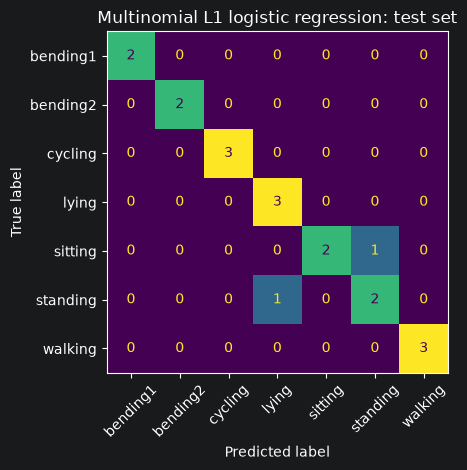

In [61]:
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

multi_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        l1_ratio=1,
        solver="saga",
        C=multi_best_C,
        max_iter=5000,
        tol=1e-3,
        random_state=552,
    ),
)

X_train_multi = X_by_l[multi_best_l]
X_test_multi = make_split_features(test_manifest, multi_best_l)

assert X_train_multi.columns.equals(X_test_multi.columns)

multi_model.fit(X_train_multi, y_train_multi)

multi_predictions = multi_model.predict(X_test_multi)
multi_probabilities = multi_model.predict_proba(X_test_multi)
activity_names = multi_model.named_steps["logisticregression"].classes_

multi_test_accuracy = accuracy_score(y_test_multi, multi_predictions)
multi_test_error = 1 - multi_test_accuracy
multi_auc = roc_auc_score(
    y_test_multi,
    multi_probabilities,
    labels=activity_names,
    multi_class="ovr",
    average="macro",
)

print(f"Cross-validation accuracy: {multi_results_df.loc[0, 'cv_accuracy']:.3f}")
print(f"Test accuracy: {multi_test_accuracy:.3f}")
print(f"Test error: {multi_test_error:.3f}")
print(f"Macro one-vs-rest AUC: {multi_auc:.3f}")

ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    multi_predictions,
    labels=activity_names,
    xticks_rotation=45,
    colorbar=False,
)
plt.title("Multinomial L1 logistic regression: test set")
plt.tight_layout()
plt.show()

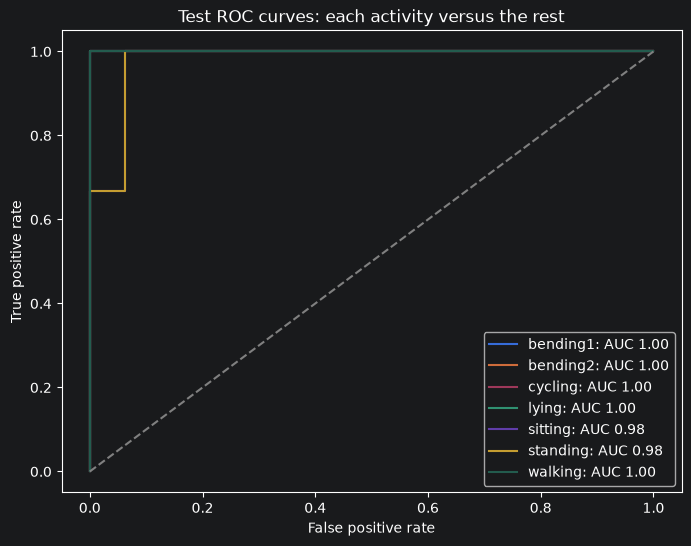

In [62]:
test_binary = label_binarize(y_test_multi, classes=activity_names)

plt.figure(figsize=(8, 6))

for i, activity in enumerate(activity_names):
    fpr, tpr, _ = roc_curve(
        test_binary[:, i],
        multi_probabilities[:, i],
    )
    plt.plot(
        fpr, tpr,
        label=f"{activity}: AUC {auc(fpr, tpr):.2f}",
    )

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Test ROC curves: each activity versus the rest")
plt.legend()
plt.show()

Four-fold cross-validation selected l=1 and C=2 for the L1 multinomial logistic regression. Its cross-validation accuracy was 92.8%. It correctly classified 17 of 19 test instances, giving a test error of 10.5%. The errors were one Sitting instance classified as Standing and one Standing instance classified as Lying. The macro one-versus-rest AUC was 0.994.

#### 2(c)ii Naive Bayes Classifier

In [63]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

def build_nb_model(kind, parameter):
    if kind == "Gaussian":
        return make_pipeline(
            StandardScaler(),
            GaussianNB(var_smoothing=parameter),
        )

    return make_pipeline(
        MinMaxScaler(clip=True),
        MultinomialNB(alpha=parameter),
    )


nb_candidates = {
    "Gaussian": [1e-9, 1e-6, 1e-3],
    "Multinomial": [0.1, 1, 10],
}

nb_results = []

for kind, parameters in nb_candidates.items():
    for l in range(1, 21):
        for parameter in parameters:
            model = build_nb_model(kind, parameter)

            scores = cross_validate(
                model,
                X_by_l[l],
                y_train_multi,
                cv=cv_multi,
                scoring={
                    "accuracy": "accuracy",
                    "balanced_accuracy": "balanced_accuracy",
                },
                error_score="raise",
            )

            nb_results.append({
                "model": kind,
                "l": l,
                "parameter": parameter,
                "cv_accuracy": scores["test_accuracy"].mean(),
                "cv_balanced_accuracy":
                    scores["test_balanced_accuracy"].mean(),
            })

nb_results_df = (
    pd.DataFrame(nb_results)
    .sort_values(
        ["model", "cv_accuracy", "cv_balanced_accuracy", "l"],
        ascending=[True, False, False, True],
    )
    .reset_index(drop=True)
)

display(nb_results_df.groupby("model", sort=False).head(5))

,model,l,parameter,cv_accuracy,cv_balanced_accuracy
0,Gaussian,2,1.000000e-03,0.883987,0.803571
1,Gaussian,1,1.000000e-03,0.870098,0.815476
2,Gaussian,2,1.000000e-09,0.855392,0.750000
3,Gaussian,2,1.000000e-06,0.855392,0.750000
4,Gaussian,1,1.000000e-06,0.811275,0.767857
60,Multinomial,13,1.000000e-01,0.825980,0.803571
61,Multinomial,1,1.000000e-01,0.812092,0.767857
62,Multinomial,12,1.000000e-01,0.811275,0.797619
63,Multinomial,10,1.000000e-01,0.811275,0.791667
64,Multinomial,18,1.000000e-01,0.810458,0.773810


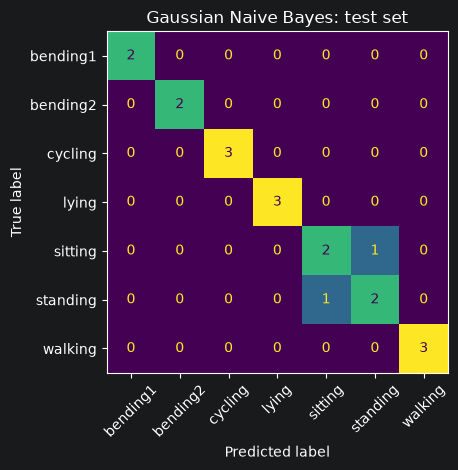

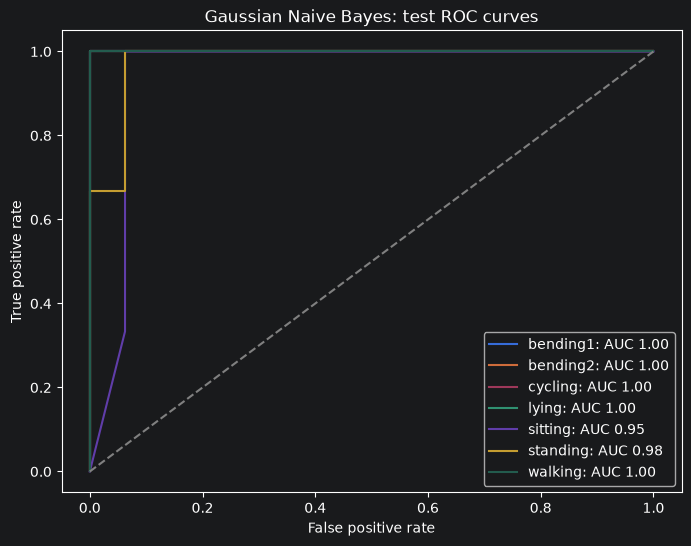

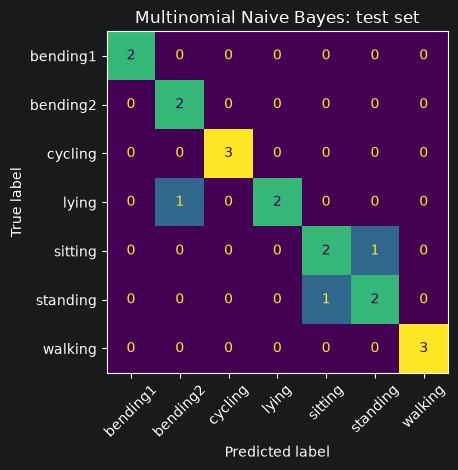

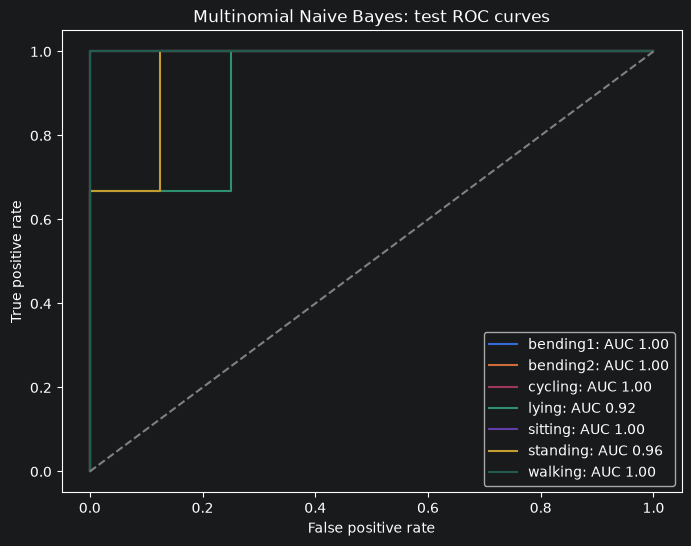

,model,l,parameter,cv_accuracy,test_accuracy,test_error,macro_auc
0,Gaussian,2,0.001,0.884,0.8947,0.1053,0.9896
1,Multinomial,13,0.100,0.826,0.8421,0.1579,0.9821


In [68]:
nb_test_results = []

for kind in ["Gaussian", "Multinomial"]:
    best = nb_results_df.loc[
        nb_results_df["model"] == kind
    ].iloc[0]

    chosen_l = int(best["l"])
    chosen_parameter = float(best["parameter"])

    model = build_nb_model(kind, chosen_parameter)
    X_train_nb = X_by_l[chosen_l]
    X_test_nb = make_split_features(test_manifest, chosen_l)

    assert X_train_nb.columns.equals(X_test_nb.columns)

    model.fit(X_train_nb, y_train_multi)
    predictions = model.predict(X_test_nb)
    probabilities = model.predict_proba(X_test_nb)
    class_names = model[-1].classes_

    test_accuracy = accuracy_score(y_test_multi, predictions)
    macro_auc = roc_auc_score(
        y_test_multi,
        probabilities,
        labels=class_names,
        multi_class="ovr",
        average="macro",
    )

    nb_test_results.append({
        "model": kind,
        "l": chosen_l,
        "parameter": chosen_parameter,
        "cv_accuracy": best["cv_accuracy"],
        "test_accuracy": test_accuracy,
        "test_error": 1 - test_accuracy,
        "macro_auc": macro_auc,
    })

    ConfusionMatrixDisplay.from_predictions(
        y_test_multi,
        predictions,
        labels=class_names,
        xticks_rotation=45,
        colorbar=False,
    )
    plt.title(f"{kind} Naive Bayes: test set")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 6))

    for i, activity in enumerate(class_names):
        fpr, tpr, _ = roc_curve(
            (y_test_multi == activity).astype(int),
            probabilities[:, i],
        )
        plt.plot(
            fpr, tpr,
            label=f"{activity}: AUC {auc(fpr, tpr):.2f}",
        )

    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"{kind} Naive Bayes: test ROC curves")
    plt.legend()
    plt.show()



nb_test_results_df = pd.DataFrame(nb_test_results)
display(nb_test_results_df.round(4))

#### 2(c)iii Better Method?
L1 multinomial logistic regression and Gaussian Naive Bayes tied on test accuracy, each correctly classifying 17 of 19 recordings. Logistic regression had higher cross-validation accuracy (92.8% versus 88.4%) and slightly higher macro AUC (0.994 versus 0.990). Multinomial Naive Bayes performed worse, correctly classifying 16 of 19 recordings. I would choose L1 multinomial logistic regression based on its stronger cross-validation result, while noting that its test accuracy tied with Gaussian Naive Bayes on this small test set.

### 3. ISLR 4.8.3

Equation (4.16) gives the normal density for each class. The density
itself is not a quadratic function because it contains an exponential.
To find the Bayes classifier, we choose the class with the largest
prior-weighted density, $\pi_k f_k(x)$. Taking its log gives us:

$$
\delta_k(x)
=\log\pi_k-\frac{1}{2}\log(2\pi)-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
+\log\pi_k-\frac{1}{2}\log(2\pi)
-\log\sigma_k-\frac{\mu_k^2}{2\sigma_k^2}.
$$

This score contains an $x^2$ term, so it is quadratic in $x$. If the
classes have different variances, the coefficient
$-\frac{1}{2\sigma_k^2}$ is different for each class. Therefore, the
$x^2$ terms do not cancel when we compare classes, and the decision
boundary comes from a quadratic equation.

### 4. ISLR 4.8.7

Let $D$ mean that a company issues a dividend. We know that
$P(D)=0.8$ and $P(\text{No})=0.2$. The two groups have means
$\mu_D=10$ and $\mu_{\text{No}}=0$, with variance $\sigma^2=36$.

Using Bayes' theorem,

$$
P(D\mid X=4)
=\frac{0.8e^{-(4-10)^2/(2\cdot36)}}
{0.8e^{-(4-10)^2/(2\cdot36)}
+0.2e^{-(4-0)^2/(2\cdot36)}}
\approx 0.752.
$$

The predicted probability that the company issues a dividend is about **75.2%**.